<a href="https://colab.research.google.com/github/Uriels28/Hands-on-6-Distance-based-Classifiers-k-Nearest-Neighbor-kNN-/blob/main/%20Hands-on%206%3A%20kNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   mean_radius  mean_texture  mean_perimeter  mean_area  mean_smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   diagnosis  
0          0  
1          0  
2          0  
3          0  
4          0  
Mejor valor de K: 9 con precisión de: 96.49%


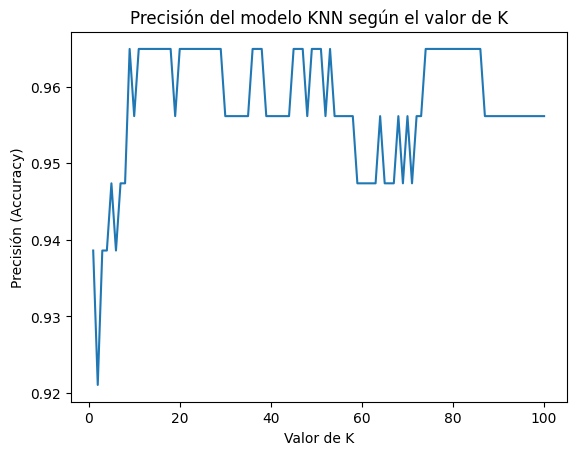

Caso de prueba generado: {'mean_radius': 22.097831099776688, 'mean_texture': 24.210720994692608, 'mean_perimeter': 158.69538291158761, 'mean_area': 2066.72583827592, 'mean_smoothness': 0.07085804836328227}
Predicción del tumor: Benigno (0)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. Cargar y examinar el conjunto de datos (con el nombre exacto de tu archivo)
data = pd.read_csv('Breast_cancer_data.csv')
print(data.head())

# 2. Separar características (X) y objetivo (Y), y normalizar
X = data.drop('diagnosis', axis=1)
Y = data['diagnosis']

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# 3. Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, Y, test_size=0.2, random_state=42)

# 4. Evaluar valores de K del 1 al 100
accuracies = []
k_values = range(1, 101)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))

best_k = k_values[np.argmax(accuracies)]
print(f"Mejor valor de K: {best_k} con precisión de: {max(accuracies):.2%}")

# 5. Graficar precisión vs valor de K
plt.plot(k_values, accuracies)
plt.xlabel('Valor de K')
plt.ylabel('Precisión (Accuracy)')
plt.title('Precisión del modelo KNN según el valor de K')
plt.show()

# 6. Reentrenar con el mejor K y predecir un caso aleatorio
model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train, y_train)

test_case = {col: np.random.uniform(X[col].min(), X[col].max()) for col in X.columns}
print("Caso de prueba generado:", test_case)

test_df = pd.DataFrame([test_case])
test_scaled = scaler.transform(test_df)

prediction = model.predict(test_scaled)[0]
resultado = "Maligno (1)" if prediction == 1 else "Benigno (0)"
print(f"Predicción del tumor: {resultado}")